In [ ]:
!nvidia-smi

Wed Nov 11 06:25:28 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   48C    P8              9W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

In [ ]:
!pip install ultralytics opencv-python matplotlib pandas numpy pyyaml seaborn -q

In [ ]:
import os
import cv2
import yaml
import random
import shutil
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from ultralytics import YOLO
from google.colab import drive

print("All libraries imported successfully!")

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings
All libraries imported successfully!


In [ ]:
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
import os

DATASET_ZIP = "/content/drive/MyDrive/Pothole.v1-raw.yolov8.zip"

DATASET_DIR = "/content/pothole_dataset"

os.makedirs(DATASET_DIR, exist_ok=True)

# Verify ZIP file exists
if os.path.exists(DATASET_ZIP):
    print("Dataset ZIP found successfully!")
else:
    print("Dataset ZIP not found. Check your Google Drive path.")

Dataset ZIP found successfully!


In [ ]:
import zipfile

with zipfile.ZipFile(DATASET_ZIP, 'r') as zip_ref:
    zip_ref.extractall(DATASET_DIR)

print("Dataset extracted successfully!")

Dataset extracted successfully!


In [ ]:
for root, dirs, files in os.walk(DATASET_DIR):

    level = root.replace(DATASET_DIR, '').count(os.sep)
    indent = ' ' * 4 * level

    print(f"{indent}{os.path.basename(root)}/")

    for file in files[:5]:
        print(f"{indent}    {file}")

pothole_dataset/
    README.roboflow.txt
    README.dataset.txt
    data.yaml
    train/
        images/
            img-592_jpg.rf.6187cc73be9786a0826c78f03b69e072.jpg
            img-579_jpg.rf.8ee8008110728a0b1d1198a9f4bbdc74.jpg
            img-424_jpg.rf.5178a699e9c56cf7ba61ede4751b6696.jpg
            img-465_jpg.rf.a4bc474c1391ceb5134993ddccf81723.jpg
            img-359_jpg.rf.6d9d100005eb3f84f3de55b14b854b18.jpg
        labels/
            img-521_jpg.rf.fa689c56eb3cd78ed57d84143cbe8d25.txt
            img-272_jpg.rf.8c1a71784795d3ee8535d76931594c9f.txt
            img-389_jpg.rf.14f171b109308eeab6e83e7795c11016.txt
            img-366_jpg.rf.d13288366b0bb14beace0ba289956039.txt
            img-16_jpg.rf.3018a4883623e53e929435fc084c2200.txt
    test/
        images/
            img-362_jpg.rf.6363ec1a7603671afb1887d9f16c03e7.jpg
            img-394_jpg.rf.2182e193f33ed5bcce45df7df27032f7.jpg
            img-65_jpg.rf.9e22afc3c2cf318239352e43a97a7241.jpg
            img-634_jpg

In [ ]:
import os

yaml_files = []

for root, dirs, files in os.walk(DATASET_DIR):
    if "data.yaml" in files:
        yaml_files.append(os.path.join(root, "data.yaml"))

if yaml_files:
    print("Found data.yaml:")
    for path in yaml_files:
        print(path)
else:
    print("No data.yaml found in the extracted dataset.")

print("\nDataset folders:")
for root, dirs, files in os.walk(DATASET_DIR):
    folders = [d for d in dirs]
    if folders:
        print(root, "->", folders)

Found data.yaml:
/content/pothole_dataset/data.yaml

Dataset folders:
/content/pothole_dataset -> ['train', 'test', 'valid']
/content/pothole_dataset/train -> ['images', 'labels']
/content/pothole_dataset/test -> ['images', 'labels']
/content/pothole_dataset/valid -> ['images', 'labels']


In [ ]:
import yaml

DATA_YAML = yaml_files[0]

with open(DATA_YAML, "r") as file:
    dataset_config = yaml.safe_load(file)

print("Dataset Configuration:")
print(dataset_config)

Dataset Configuration:
{'train': '../train/images', 'val': '../valid/images', 'test': '../test/images', 'nc': 1, 'names': ['pothole'], 'roboflow': {'workspace': 'brad-dwyer', 'project': 'pothole-voxrl', 'version': 1, 'license': 'ODbL v1.0', 'url': 'https://universe.roboflow.com/brad-dwyer/pothole-voxrl/dataset/1'}}


In [ ]:
import os

IMAGE_EXTENSIONS = (".jpg", ".jpeg", ".png", ".bmp", ".webp")

image_files = []
label_files = []

for root, dirs, files in os.walk(DATASET_DIR):
    for file in files:
        path = os.path.join(root, file)

        if file.lower().endswith(IMAGE_EXTENSIONS):
            image_files.append(path)

        elif file.lower().endswith(".txt"):
            label_files.append(path)

print("Total Images:", len(image_files))
print("Total Label Files:", len(label_files))

print("\nSample Images:")
for path in image_files[:5]:
    print(path)

print("\nSample Labels:")
for path in label_files[:5]:
    print(path)

Total Images: 665
Total Label Files: 667

Sample Images:
/content/pothole_dataset/train/images/img-592_jpg.rf.6187cc73be9786a0826c78f03b69e072.jpg
/content/pothole_dataset/train/images/img-579_jpg.rf.8ee8008110728a0b1d1198a9f4bbdc74.jpg
/content/pothole_dataset/train/images/img-424_jpg.rf.5178a699e9c56cf7ba61ede4751b6696.jpg
/content/pothole_dataset/train/images/img-465_jpg.rf.a4bc474c1391ceb5134993ddccf81723.jpg
/content/pothole_dataset/train/images/img-359_jpg.rf.6d9d100005eb3f84f3de55b14b854b18.jpg

Sample Labels:
/content/pothole_dataset/README.roboflow.txt
/content/pothole_dataset/README.dataset.txt
/content/pothole_dataset/train/labels/img-521_jpg.rf.fa689c56eb3cd78ed57d84143cbe8d25.txt
/content/pothole_dataset/train/labels/img-272_jpg.rf.8c1a71784795d3ee8535d76931594c9f.txt
/content/pothole_dataset/train/labels/img-389_jpg.rf.14f171b109308eeab6e83e7795c11016.txt


In [ ]:
from pathlib import Path

label_stems = {Path(p).stem for p in label_files}

matched = [
    p for p in image_files
    if Path(p).stem in label_stems
]

unmatched = [
    p for p in image_files
    if Path(p).stem not in label_stems
]

print("Images with matching labels:", len(matched))
print("Images without matching labels:", len(unmatched))

if unmatched:
    print("\nFirst 10 unmatched images:")
    for p in unmatched[:10]:
        print(p)

Images with matching labels: 665
Images without matching labels: 0


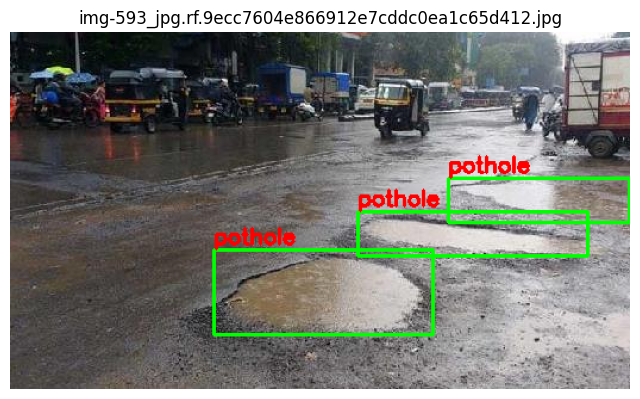

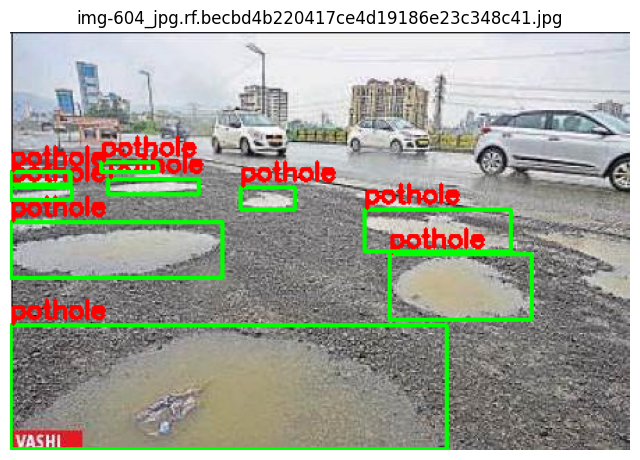

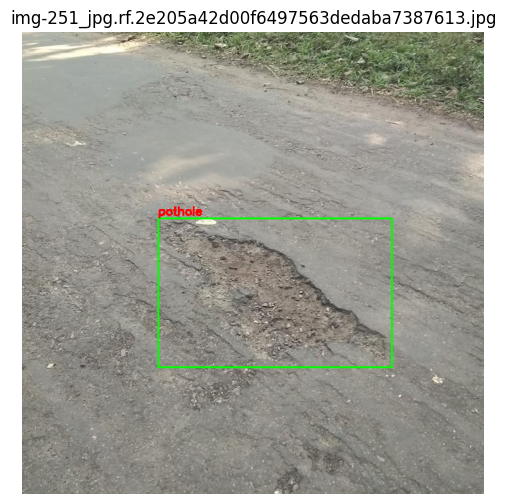

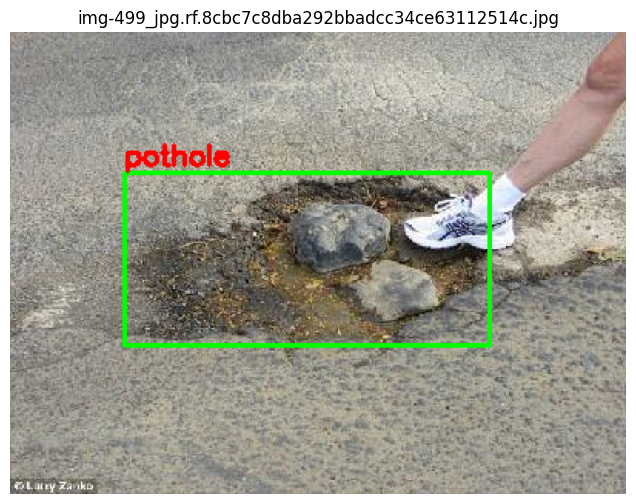

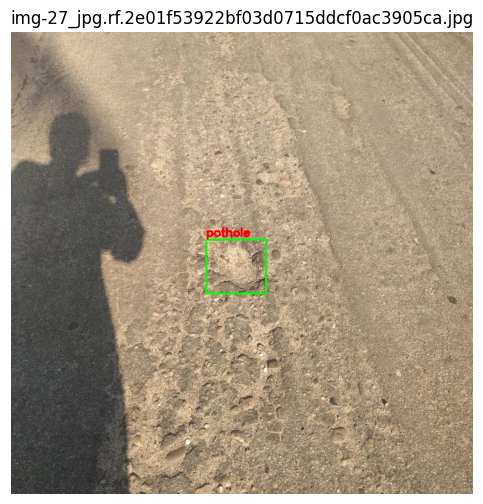

In [ ]:
import os
import random
import cv2
import matplotlib.pyplot as plt
from pathlib import Path

# Get class names from data.yaml
class_names = dataset_config.get("names", {0: "pothole"})

if isinstance(class_names, list):
    class_names = {i: name for i, name in enumerate(class_names)}

# Select 5 random images
sample_images = random.sample(image_files, min(5, len(image_files)))

for image_path in sample_images:

    image = cv2.imread(image_path)
    image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

    h, w, _ = image.shape

    # Find corresponding label file
    label_path = None
    for path in label_files:
        if Path(path).stem == Path(image_path).stem:
            label_path = path
            break

    if label_path and os.path.exists(label_path):

        with open(label_path, "r") as f:
            lines = f.readlines()

        for line in lines:
            values = line.strip().split()

            if len(values) != 5:
                continue

            class_id, x_center, y_center, box_width, box_height = map(float, values)

            x1 = int((x_center - box_width / 2) * w)
            y1 = int((y_center - box_height / 2) * h)
            x2 = int((x_center + box_width / 2) * w)
            y2 = int((y_center + box_height / 2) * h)

            cv2.rectangle(image, (x1, y1), (x2, y2), (0, 255, 0), 2)

            name = class_names.get(int(class_id), str(int(class_id)))
            cv2.putText(
                image, name, (x1, max(20, y1 - 5)),
                cv2.FONT_HERSHEY_SIMPLEX, 0.6, (255, 0, 0), 2
            )

    plt.figure(figsize=(8, 6))
    plt.imshow(image)
    plt.title(Path(image_path).name)
    plt.axis("off")
    plt.show()

In [ ]:
import os
import yaml

with open(DATA_YAML, "r") as file:
    config = yaml.safe_load(file)

print("Dataset configuration:")
print(config)

# Base directory containing data.yaml
yaml_dir = os.path.dirname(DATA_YAML)

for split in ["train", "val", "test"]:
    split_path = config.get(split)

    if split_path:
        if os.path.isabs(split_path):
            full_path = split_path
        else:
            full_path = os.path.normpath(os.path.join(yaml_dir, split_path))

        print(f"\n{split.upper()} path: {full_path}")
        print("Exists:", os.path.exists(full_path))

        if os.path.exists(full_path):
            print("Files:", len(os.listdir(full_path)))
    else:
        print(f"\n{split.upper()} path is not specified.")

Dataset configuration:
{'train': '../train/images', 'val': '../valid/images', 'test': '../test/images', 'nc': 1, 'names': ['pothole'], 'roboflow': {'workspace': 'brad-dwyer', 'project': 'pothole-voxrl', 'version': 1, 'license': 'ODbL v1.0', 'url': 'https://universe.roboflow.com/brad-dwyer/pothole-voxrl/dataset/1'}}

TRAIN path: /content/train/images
Exists: False

VAL path: /content/valid/images
Exists: False

TEST path: /content/test/images
Exists: False


In [ ]:
print("Number of classes:", config.get("nc"))
print("Class names:", config.get("names"))

Number of classes: 1
Class names: ['pothole']


In [ ]:
from ultralytics import YOLO

# Load pretrained YOLOv8s model
model = YOLO("yolov8s.pt")

# Start training
results = model.train(
    data=DATA_YAML,
    epochs=100,
    imgsz=640,
    batch=16,
    optimizer="AdamW",
    lr0=0.001,
    patience=20,
    device=0,
    project="/content/runs/pothole",
    name="yolov8s_100_epochs",
    seed=42,
    plots=True,
    save=True
)

Ultralytics 8.4.210 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/pothole_dataset/data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=100, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=None, kobj=1.0, line_width=None, lr0=0.001, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8s.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=yolov8s_100_epochs, nbs=64, nms=None, opset=None, o

In [ ]:
import os

BEST_MODEL = "/content/runs/pothole/yolov8s_100_epochs/weights/best.pt"

print("Best model exists:", os.path.exists(BEST_MODEL))
print("Best model path:", BEST_MODEL)

Best model exists: True
Best model path: /content/runs/pothole/yolov8s_100_epochs/weights/best.pt


In [ ]:
from ultralytics import YOLO

model = YOLO(BEST_MODEL)

metrics = model.val(
    data=DATA_YAML,
    split="test",
    imgsz=640,
    batch=16,
    device=0
)

print("Precision:", metrics.box.mp)
print("Recall:", metrics.box.mr)
print("mAP50:", metrics.box.map50)
print("mAP50-95:", metrics.box.map)

Ultralytics 8.4.210 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
Model summary (fused): 72 layers, 11,125,971 parameters, 0 gradients, 28.4 GFLOPs
WARNING ⚠️ val: Slow image access detected (ping: 0.0±0.0 ms, read: 40.0±27.3 MB/s, size: 83.5 KB). Use local storage instead of remote/mounted storage for better performance. See https://docs.ultralytics.com/guides/model-training-tips
val: Scanning /content/pothole_dataset/test/labels... 67 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 67/67 637.6it/s 0.1s
val: New cache created: /content/pothole_dataset/test/labels.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 5/5 2.3it/s 2.2s
                   all         67        154      0.838       0.67      0.786      0.508
Speed: 2.2ms preprocess, 9.3ms inference, 0.0ms loss, 2.2ms postprocess per image
Results saved to /content/runs/detect/val
Precision: 0.8376696177075346
Recall: 0.6701743536608172
mAP50:

In [ ]:
from ultralytics import YOLO
import matplotlib.pyplot as plt
import glob
import os

BEST_MODEL = "/content/runs/pothole/yolov8s_100_epochs/weights/best.pt"

model = YOLO(BEST_MODEL)

TEST_IMAGES = os.path.join(DATASET_DIR, "test", "images")

image_paths = glob.glob(TEST_IMAGES + "/*.jpg")[:10]

results = model.predict(
    source=image_paths,
    conf=0.25,
    save=True
)

print("Predictions saved successfully!")


0: 640x640 1 pothole, 9.3ms
1: 640x640 2 potholes, 9.3ms
2: 640x640 1 pothole, 9.3ms
3: 640x640 9 potholes, 9.3ms
4: 640x640 8 potholes, 9.3ms
5: 640x640 2 potholes, 9.3ms
6: 640x640 5 potholes, 9.3ms
7: 640x640 2 potholes, 9.3ms
8: 640x640 4 potholes, 9.3ms
9: 640x640 2 potholes, 9.3ms
Speed: 3.0ms preprocess, 9.3ms inference, 1.9ms postprocess per image at shape (1, 3, 640, 640)
Results saved to /content/runs/detect/predict
Predictions saved successfully!


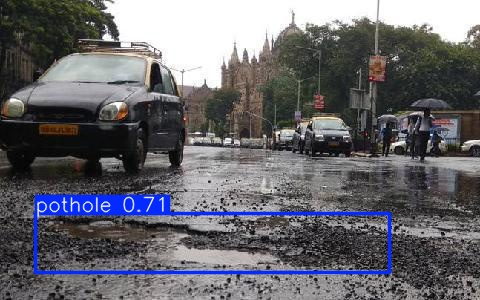

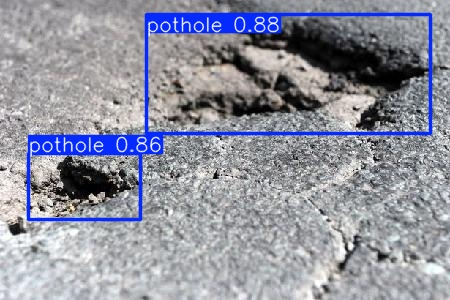

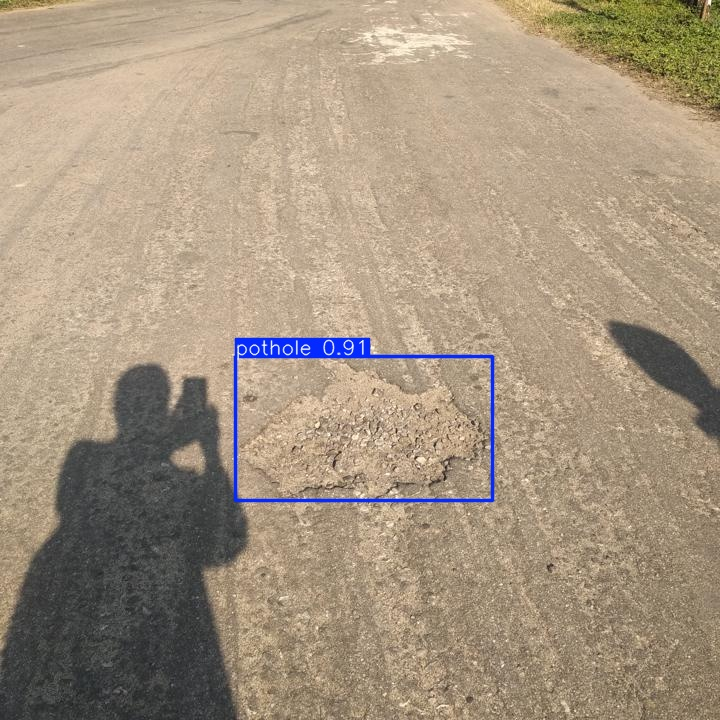

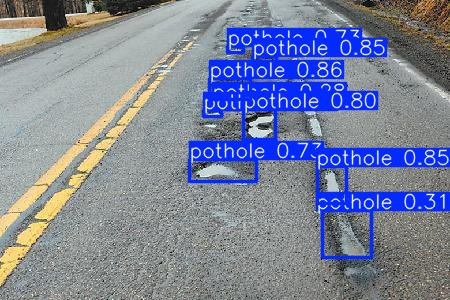

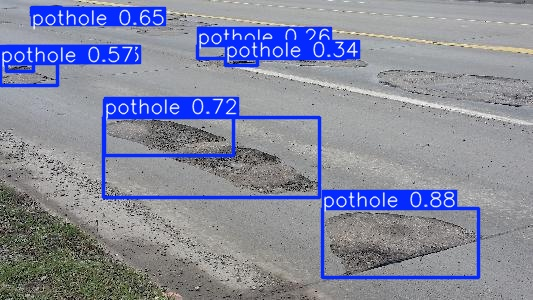

In [ ]:
from IPython.display import Image, display
import glob
import os

prediction_dir = results[0].save_dir

predicted_images = glob.glob(
    os.path.join(prediction_dir, "*.jpg")
)

for img in predicted_images[:5]:
    display(Image(filename=img, width=600))

In [ ]:
from ultralytics import YOLO

model = YOLO("yolov8s.pt")

results = model.train(
    data=DATA_YAML,
    epochs=150,
    imgsz=800,
    batch=8,
    optimizer="AdamW",
    lr0=0.001,
    patience=30,
    device=0,
    project="/content/runs/pothole",
    name="yolov8s_improved",
    seed=42,
    plots=True,
    save=True
)

Ultralytics 8.4.210 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=8, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/pothole_dataset/data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=150, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=800, iou=None, kobj=1.0, line_width=None, lr0=0.001, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8s.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=yolov8s_improved, nbs=64, nms=None, opset=None, opti

In [ ]:
from ultralytics import YOLO

BEST_MODEL = "/content/runs/pothole/yolov8s_improved/weights/best.pt"

model = YOLO(BEST_MODEL)

test_results = model.val(
    data=DATA_YAML,
    split="test",
    imgsz=800,
    batch=8,
    device=0
)

print("\nFINAL TEST RESULTS")
print("Precision:", test_results.box.mp)
print("Recall:", test_results.box.mr)
print("mAP50:", test_results.box.map50)
print("mAP50-95:", test_results.box.map)

Ultralytics 8.4.210 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
Model summary (fused): 72 layers, 11,125,971 parameters, 0 gradients, 28.4 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 1417.0±427.8 MB/s, size: 83.5 KB)
val: Scanning /content/pothole_dataset/test/labels.cache... 67 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 67/67 25.5Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 9/9 3.9it/s 2.3s
                   all         67        154      0.697      0.717      0.719      0.463
Speed: 2.0ms preprocess, 15.0ms inference, 0.0ms loss, 1.8ms postprocess per image
Results saved to /content/runs/detect/val-2

FINAL TEST RESULTS
Precision: 0.6970095539616011
Recall: 0.7170284110691751
mAP50: 0.7192085138289706
mAP50-95: 0.4627156176779609


In [ ]:
from ultralytics import YOLO

model = YOLO("yolo11s.pt")

print("YOLO11s model downloaded successfully!")

YOLO11s model downloaded successfully!


In [ ]:
results = model.train(
    data="/content/pothole_dataset/data.yaml",
    epochs=100,
    imgsz=640,
    batch=16,
    optimizer="AdamW",
    lr0=0.001,
    patience=20,
    device=0,
    project="/content/runs/pothole",
    name="yolo11s_baseline",
    seed=42,
    plots=True
)

Ultralytics 8.4.210 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/pothole_dataset/data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=100, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=None, kobj=1.0, line_width=None, lr0=0.001, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo11s.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=yolo11s_baseline, nbs=64, nms=None, opset=None, opt

In [ ]:
import os

BEST_MODEL = "/content/runs/pothole/yolo11s_baseline/weights/best.pt"

print("Model saved:", os.path.exists(BEST_MODEL))
print("Model path:", BEST_MODEL)

Model saved: True
Model path: /content/runs/pothole/yolo11s_baseline/weights/best.pt


In [ ]:
from ultralytics import YOLO

model = YOLO(BEST_MODEL)

val_results = model.val(
    data=DATA_YAML,
    split="val",
    imgsz=640,
    batch=16,
    device=0
)

print("\nYOLO11s VALIDATION RESULTS")
print("Precision:", val_results.box.mp)
print("Recall:", val_results.box.mr)
print("mAP50:", val_results.box.map50)
print("mAP50-95:", val_results.box.map)

Ultralytics 8.4.210 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLO11s summary (fused): 100 layers, 9,413,187 parameters, 0 gradients, 21.4 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 1993.0±1061.7 MB/s, size: 90.2 KB)
val: Scanning /content/pothole_dataset/valid/labels.cache... 133 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 133/133 37.2Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 9/9 2.7it/s 3.3s
                   all        133        330      0.778      0.715      0.788      0.509
Speed: 2.3ms preprocess, 8.8ms inference, 0.0ms loss, 2.4ms postprocess per image
Results saved to /content/runs/detect/val-3

YOLO11s VALIDATION RESULTS
Precision: 0.7777141496686847
Recall: 0.7151515151515152
mAP50: 0.7882742346506323
mAP50-95: 0.5093986052184608


In [ ]:
test_results = model.val(
    data=DATA_YAML,
    split="test",
    imgsz=640,
    batch=16,
    device=0
)

print("\nYOLO11s FINAL TEST RESULTS")
print("Precision:", test_results.box.mp)
print("Recall:", test_results.box.mr)
print("mAP50:", test_results.box.map50)
print("mAP50-95:", test_results.box.map)

Ultralytics 8.4.210 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLO11s summary (fused): 100 layers, 9,413,187 parameters, 0 gradients, 21.4 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 1640.6±728.2 MB/s, size: 71.8 KB)
val: Scanning /content/pothole_dataset/test/labels.cache... 67 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 67/67 14.1Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 5/5 1.6it/s 3.2s
                   all         67        154      0.801      0.701      0.805      0.538
Speed: 6.2ms preprocess, 11.7ms inference, 0.0ms loss, 6.6ms postprocess per image
Results saved to /content/runs/detect/val-4

YOLO11s FINAL TEST RESULTS
Precision: 0.8005137547289438
Recall: 0.7012987012987013
mAP50: 0.8054511849351822
mAP50-95: 0.5380907272854054


In [ ]:
import os
import glob
from ultralytics import YOLO

TEST_IMAGES = "/content/pothole_dataset/test/images"

predictions = model.predict(
    source=TEST_IMAGES,
    imgsz=640,
    conf=0.25,
    save=True
)

print("Prediction results saved!")
print("Location:", predictions[0].save_dir)


image 1/67 /content/pothole_dataset/test/images/img-105_jpg.rf.3fe9dff3d1631e79ecb480ff403bcb86.jpg: 640x640 1 pothole, 15.4ms
image 2/67 /content/pothole_dataset/test/images/img-107_jpg.rf.2e40485785f6e5e2efec404301b235c2.jpg: 640x640 2 potholes, 15.5ms
image 3/67 /content/pothole_dataset/test/images/img-146_jpg.rf.61be25b3053a51f622a244980545df2b.jpg: 640x640 1 pothole, 15.5ms
image 4/67 /content/pothole_dataset/test/images/img-161_jpg.rf.211541e7178a4a93ec0680f26b905427.jpg: 640x640 1 pothole, 15.5ms
image 5/67 /content/pothole_dataset/test/images/img-168_jpg.rf.af3590e07b06b43e91fa53990ff94af3.jpg: 640x640 3 potholes, 15.5ms
image 6/67 /content/pothole_dataset/test/images/img-179_jpg.rf.8632eb0d9b75fefe144829e67b75015a.jpg: 640x640 4 potholes, 15.6ms
image 7/67 /content/pothole_dataset/test/images/img-195_jpg.rf.f77a8f4d432a9a89235168ff8e09a650.jpg: 640x640 4 potholes, 15.5ms
image 8/67 /content/pothole_dataset/test/images/img-196_jpg.rf.c1e105382a0bb8d329959cea45173cdf.jpg: 640x6

In [ ]:
from ultralytics import YOLO

model = YOLO("yolo26s.pt")

results = model.train(
    data="/content/pothole_dataset/data.yaml",
    epochs=100,
    imgsz=640,
    batch=16,
    patience=20,
    device=0,
    project="/content/runs/pothole",
    name="yolo26s_baseline",
    seed=42,
    plots=True
)

Ultralytics 8.4.210 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/pothole_dataset/data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=100, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=None, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo26s.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=yolo26s_baseline, nbs=64, nms=None, opset=None, opti

In [ ]:
print("Training completed!")
print("Best model:", results.save_dir / "weights" / "best.pt")
print("Last model:", results.save_dir / "weights" / "last.pt")

Training completed!
Best model: /content/runs/pothole/yolo26s_baseline/weights/best.pt
Last model: /content/runs/pothole/yolo26s_baseline/weights/last.pt


In [ ]:
from ultralytics import YOLO

best_model = YOLO("/content/runs/pothole/yolo26s_baseline/weights/best.pt")

metrics = best_model.val(
    data="/content/pothole_dataset/data.yaml",
    split="val",
    imgsz=640,
    batch=16,
    device=0,
    plots=True
)

print("Precision:", metrics.box.mp)
print("Recall:", metrics.box.mr)
print("mAP50:", metrics.box.map50)
print("mAP50-95:", metrics.box.map)

Ultralytics 8.4.210 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLO26s summary (fused): 120 layers, 9,465,567 parameters, 0 gradients, 20.8 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 1573.8±985.1 MB/s, size: 90.2 KB)
val: Scanning /content/pothole_dataset/valid/labels.cache... 133 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 133/133 50.7Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 9/9 2.9it/s 3.1s
                   all        133        330      0.865      0.718      0.818      0.529
Speed: 2.4ms preprocess, 9.5ms inference, 0.0ms loss, 3.0ms postprocess per image
Results saved to /content/runs/detect/val-5
Precision: 0.8649348877823968
Recall: 0.7180065090826244
mAP50: 0.8182992012929784
mAP50-95: 0.5291908887735295


In [ ]:
test_metrics = best_model.val(
    data="/content/pothole_dataset/data.yaml",
    split="test",
    imgsz=640,
    batch=16,
    device=0,
    plots=True
)

print("YOLO26s TEST RESULTS")
print("Precision:", test_metrics.box.mp)
print("Recall:", test_metrics.box.mr)
print("mAP@50:", test_metrics.box.map50)
print("mAP@50-95:", test_metrics.box.map)

Ultralytics 8.4.210 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLO26s summary (fused): 120 layers, 9,465,567 parameters, 0 gradients, 20.8 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 1489.4±797.5 MB/s, size: 71.8 KB)
val: Scanning /content/pothole_dataset/test/labels.cache... 67 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 67/67 15.6Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 5/5 2.1it/s 2.4s
                   all         67        154      0.836      0.753      0.831      0.545
Speed: 3.5ms preprocess, 10.4ms inference, 0.0ms loss, 4.1ms postprocess per image
Results saved to /content/runs/detect/val-6
YOLO26s TEST RESULTS
Precision: 0.8358722130068246
Recall: 0.7532467532467533
mAP@50: 0.8308409083825545
mAP@50-95: 0.5451364035678645


In [ ]:
import glob
from IPython.display import Image, display

test_images = glob.glob(
    "/content/pothole_dataset/test/images/*"
)

predictions = best_model.predict(
    source=test_images[:10],
    imgsz=640,
    conf=0.25,
    save=True
)

print("Predictions saved successfully!")


0: 640x640 (no detections), 12.1ms
1: 640x640 2 potholes, 12.1ms
2: 640x640 1 pothole, 12.1ms
3: 640x640 8 potholes, 12.1ms
4: 640x640 6 potholes, 12.1ms
5: 640x640 4 potholes, 12.1ms
6: 640x640 4 potholes, 12.1ms
7: 640x640 3 potholes, 12.1ms
8: 640x640 4 potholes, 12.1ms
9: 640x640 2 potholes, 12.1ms
Speed: 1.7ms preprocess, 12.1ms inference, 1.0ms postprocess per image at shape (1, 3, 640, 640)
Results saved to /content/runs/detect/predict-3
Predictions saved successfully!


In [ ]:
from ultralytics import YOLO

model = YOLO(
    "/content/runs/pothole/yolo26s_baseline/weights/best.pt"
)

results = model.val(
    data="/content/pothole_dataset/data.yaml",
    split="test",
    imgsz=640,
    plots=True,
    device=0
)

print("Confusion matrix and evaluation plots generated!")

Ultralytics 8.4.210 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLO26s summary (fused): 120 layers, 9,465,567 parameters, 0 gradients, 20.8 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 1693.0±488.6 MB/s, size: 64.9 KB)
val: Scanning /content/pothole_dataset/test/labels.cache... 67 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 67/67 11.2Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 5/5 2.1it/s 2.4s
                   all         67        154      0.836      0.753      0.831      0.545
Speed: 4.3ms preprocess, 10.1ms inference, 0.0ms loss, 3.6ms postprocess per image
Results saved to /content/runs/detect/val-7
Confusion matrix and evaluation plots generated!


In [ ]:
import os

folder = "/content/runs/detect/val-7"

print(os.listdir(folder))

['BoxF1_curve.png', 'BoxR_curve.png', 'val_batch0_labels.jpg', 'val_batch1_pred.jpg', 'val_batch1_labels.jpg', 'BoxPR_curve.png', 'confusion_matrix_normalized.png', 'val_batch2_labels.jpg', 'val_batch2_pred.jpg', 'confusion_matrix.png', 'BoxP_curve.png', 'val_batch0_pred.jpg']


In [ ]:
import os
from IPython.display import display, Image

results_folder = "/content/runs/detect/val-7"

print("Available evaluation plots:")

for file in os.listdir(results_folder):
    if file.endswith(".png"):
        print(file)

Available evaluation plots:
BoxF1_curve.png
BoxR_curve.png
BoxPR_curve.png
confusion_matrix_normalized.png
confusion_matrix.png
BoxP_curve.png


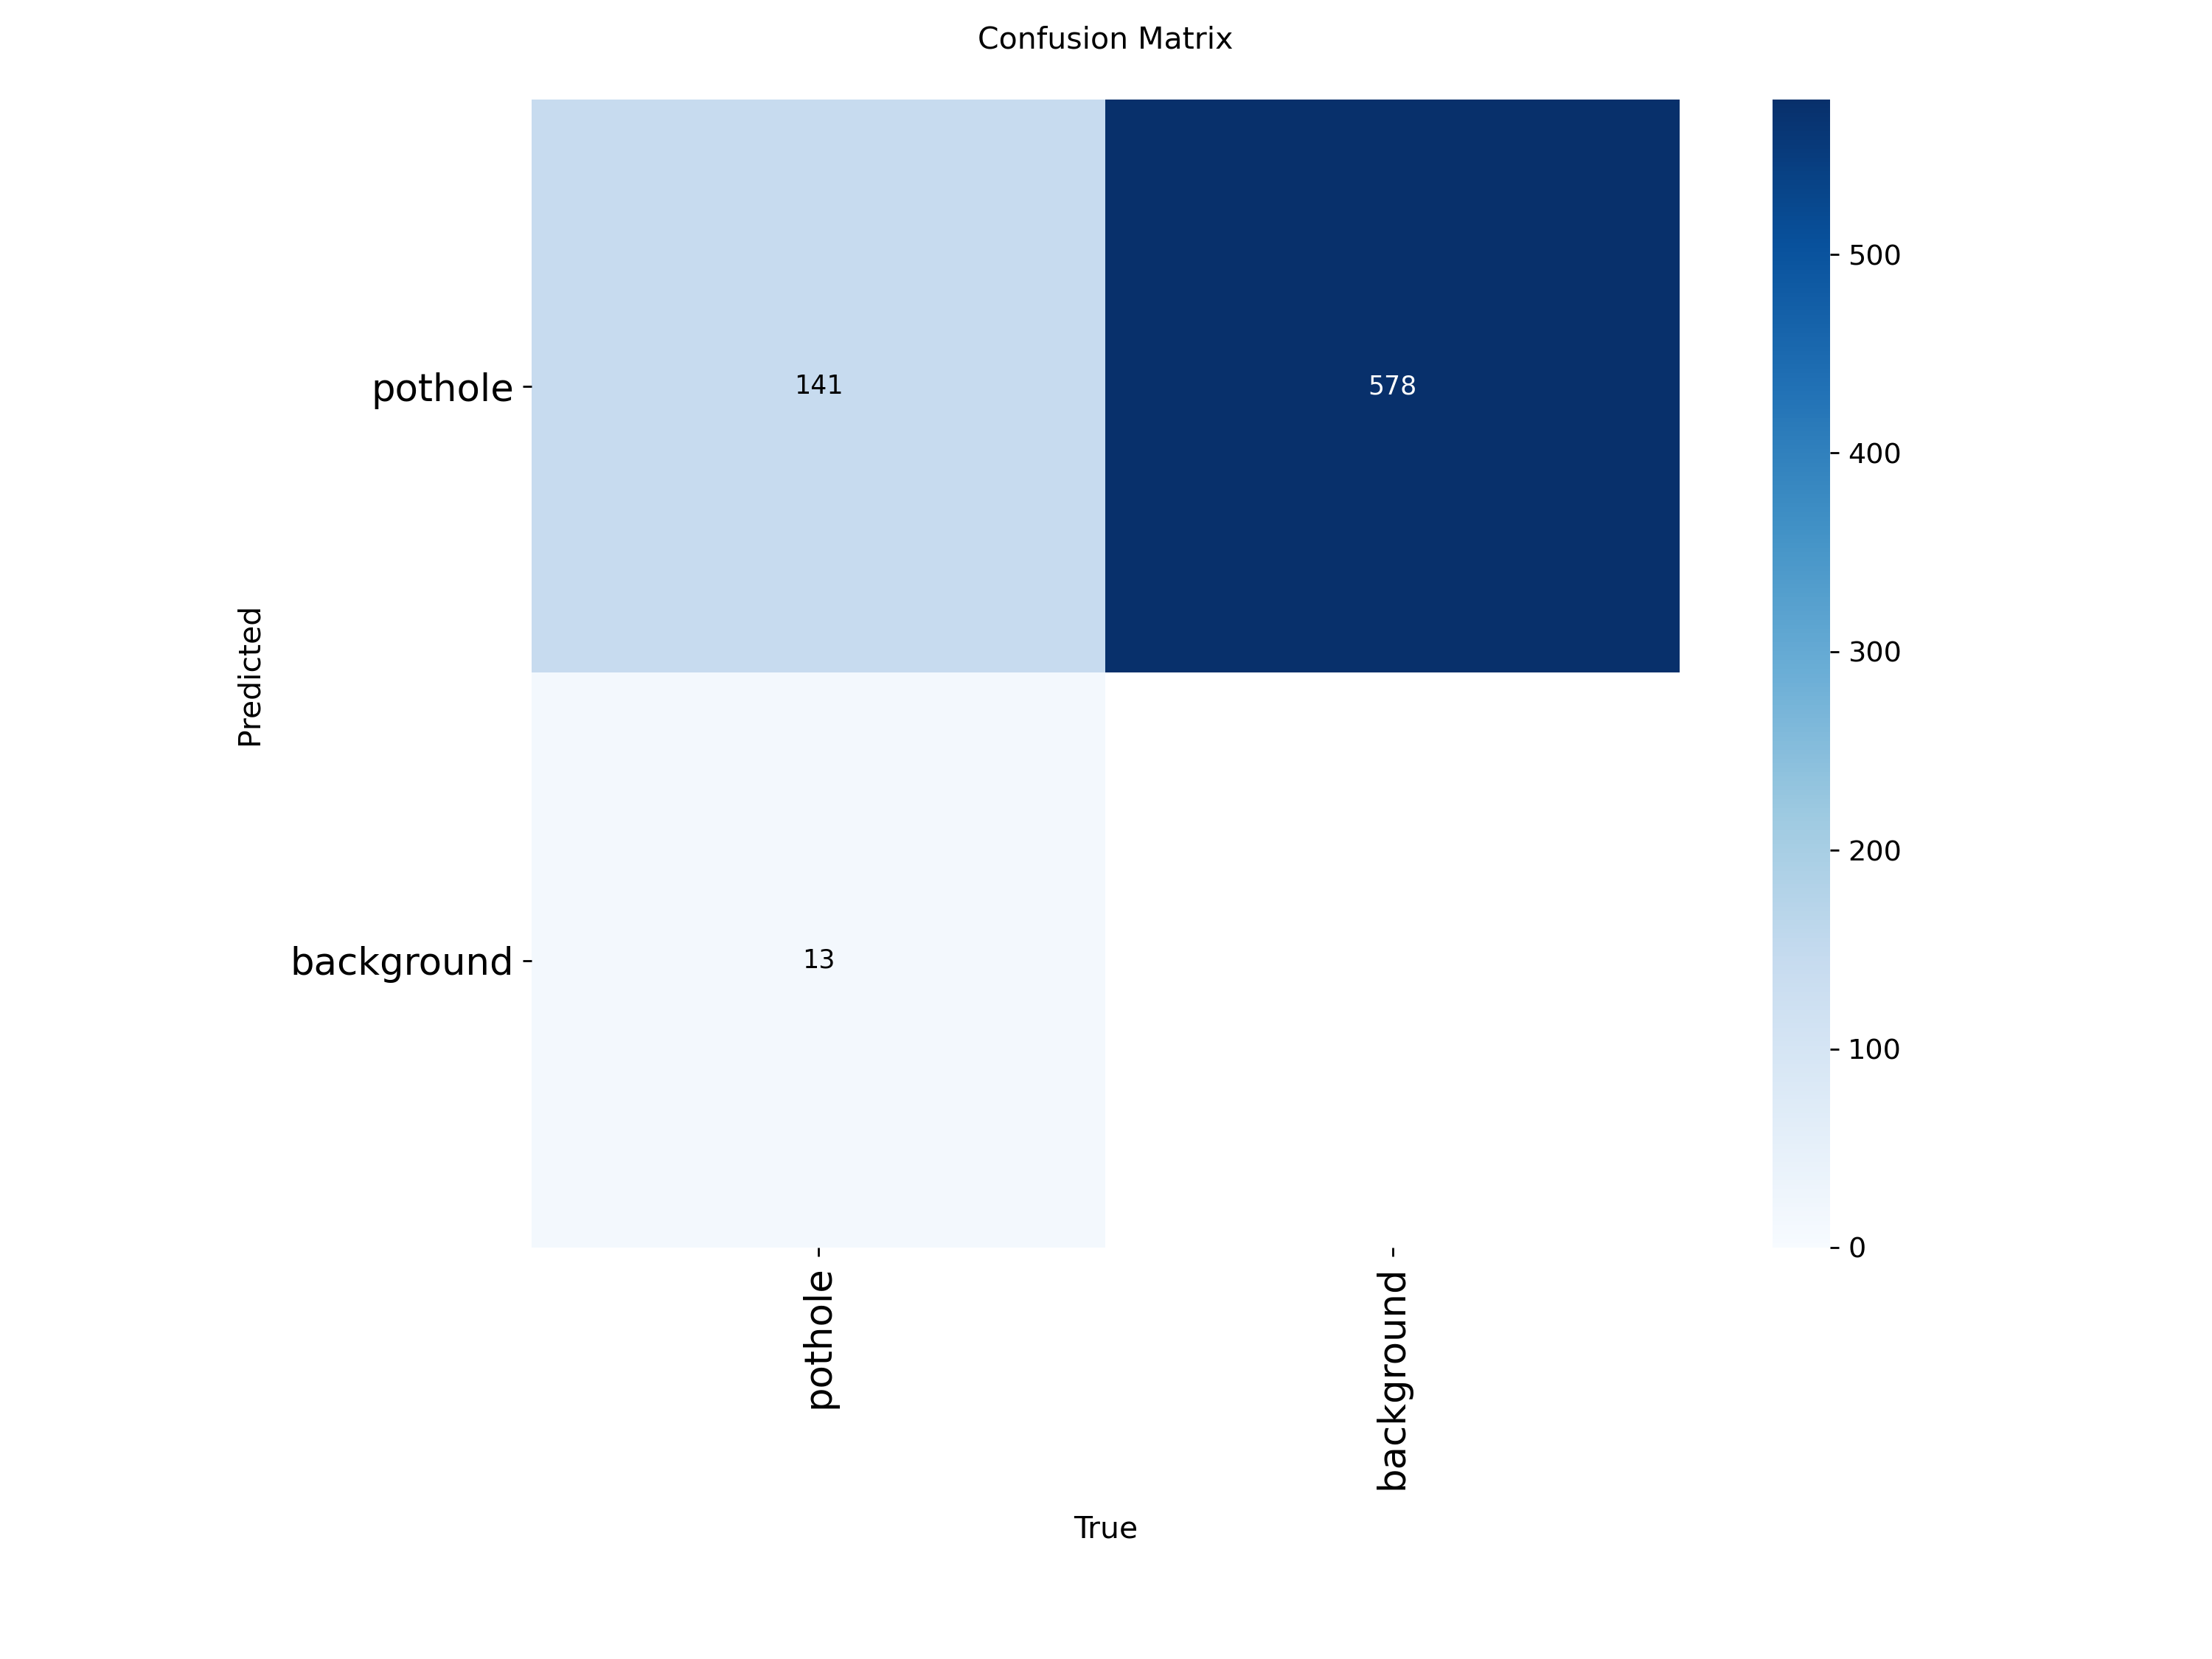

In [ ]:
display(
    Image(filename="/content/runs/detect/val-7/confusion_matrix.png")
)

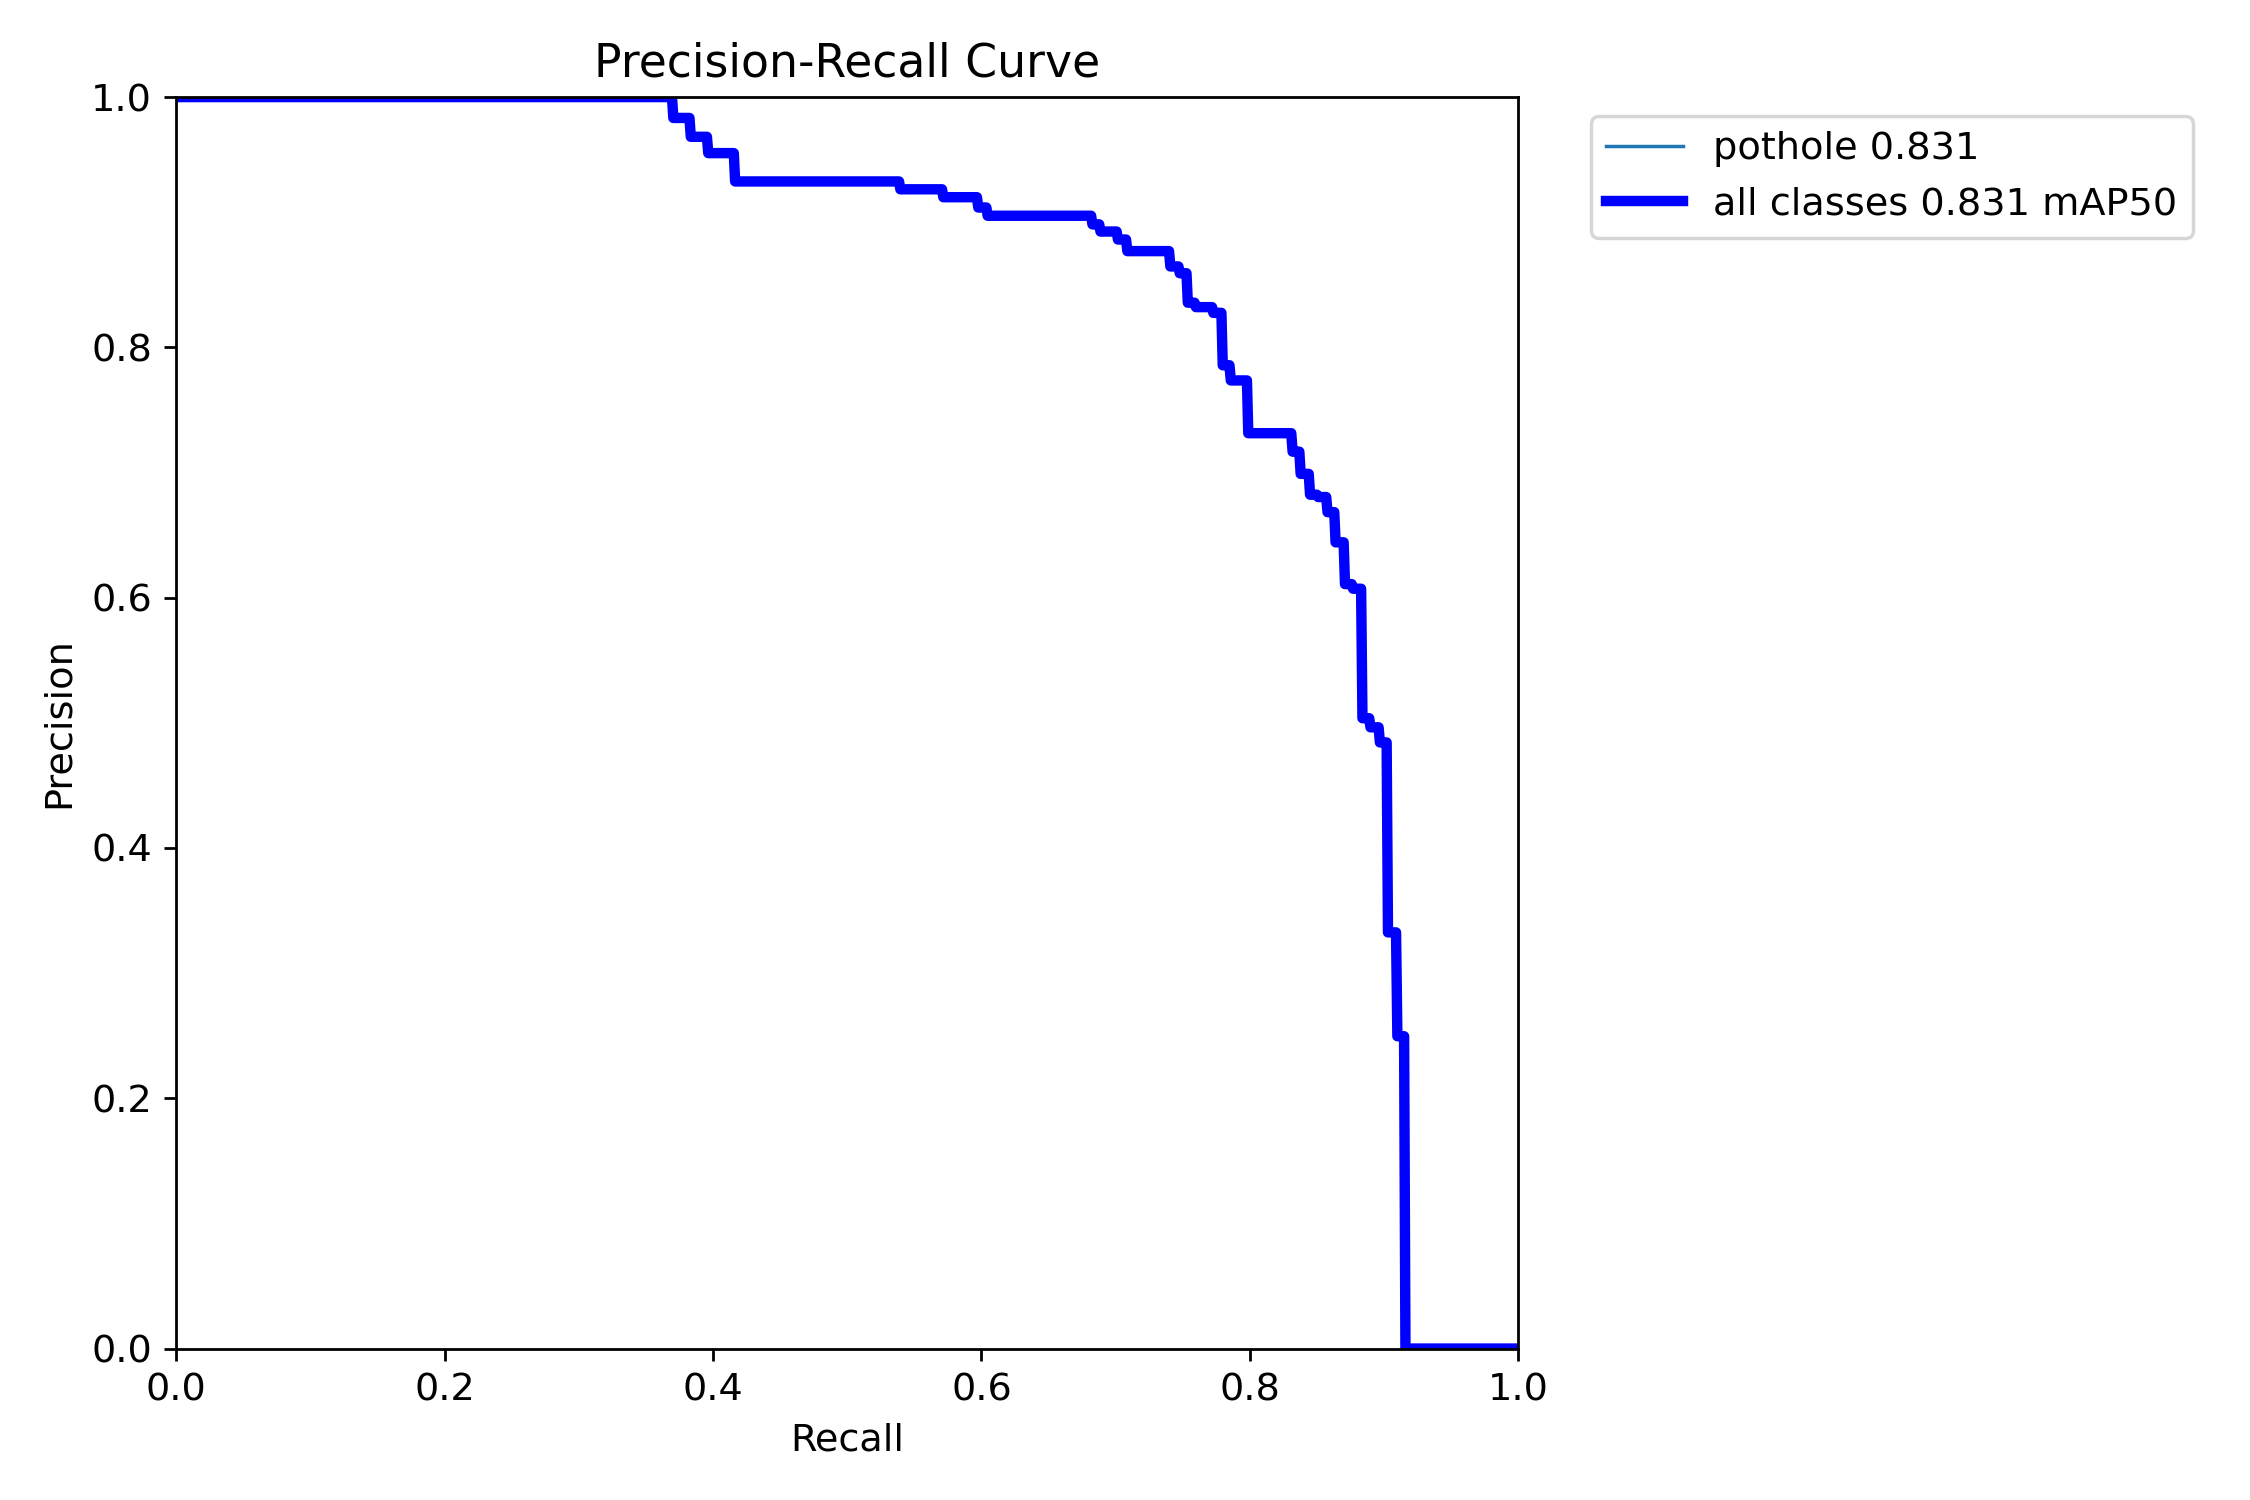

In [ ]:
display(
    Image(filename="/content/runs/detect/val-7/BoxPR_curve.png")
)

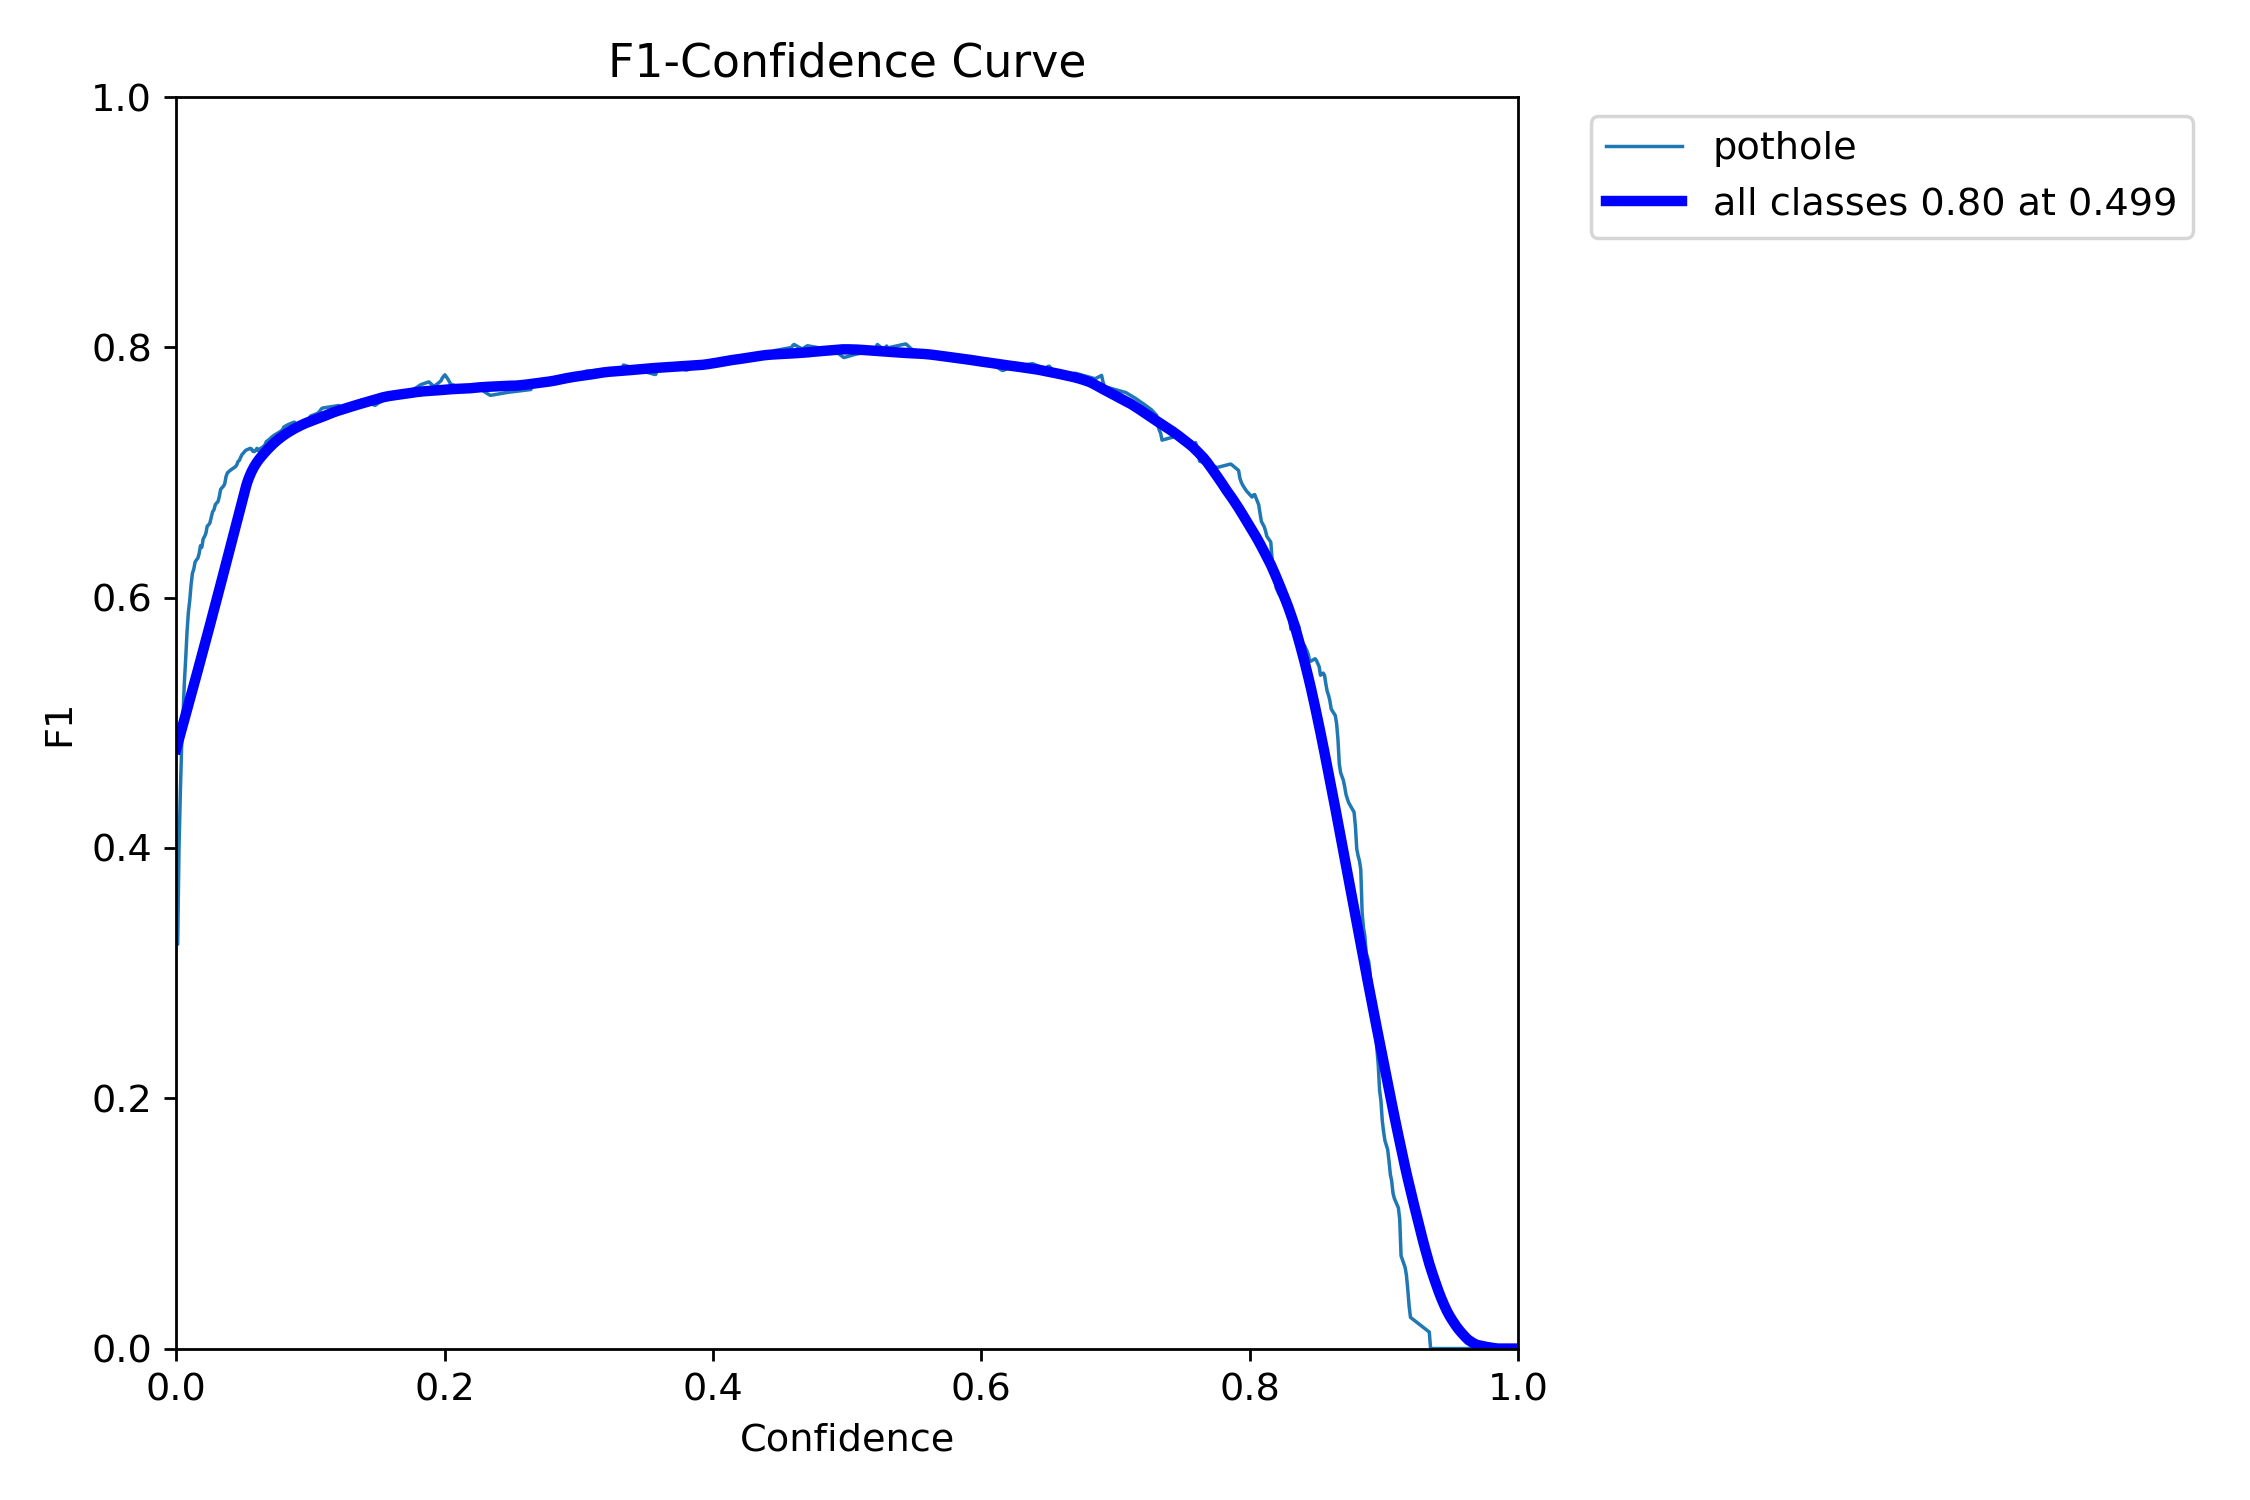

In [ ]:
display(
    Image(filename="/content/runs/detect/val-7/BoxF1_curve.png")
)

In [ ]:
from ultralytics import YOLO
import glob

model = YOLO(
    "/content/runs/pothole/yolo26s_baseline/weights/best.pt"
)

test_images = glob.glob(
    "/content/pothole_dataset/test/images/*"
)

results = model.predict(
    source=test_images[:15],
    imgsz=640,
    conf=0.499,
    save=True,
    project="/content/pothole_predictions",
    name="yolo26s_conf_0499"
)

print("Predictions generated successfully!")


0: 640x640 (no detections), 9.7ms
1: 640x640 2 potholes, 9.7ms
2: 640x640 1 pothole, 9.7ms
3: 640x640 8 potholes, 9.7ms
4: 640x640 4 potholes, 9.7ms
5: 640x640 3 potholes, 9.7ms
6: 640x640 4 potholes, 9.7ms
7: 640x640 2 potholes, 9.7ms
8: 640x640 4 potholes, 9.7ms
9: 640x640 1 pothole, 9.7ms
10: 640x640 1 pothole, 9.7ms
11: 640x640 1 pothole, 9.7ms
12: 640x640 4 potholes, 9.7ms
13: 640x640 2 potholes, 9.7ms
14: 640x640 1 pothole, 9.7ms
Speed: 1.8ms preprocess, 9.7ms inference, 1.0ms postprocess per image at shape (1, 3, 640, 640)
Results saved to /content/pothole_predictions/yolo26s_conf_0499
Predictions generated successfully!


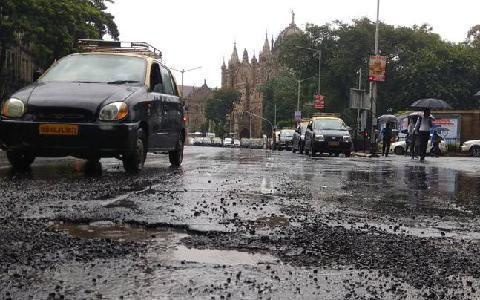

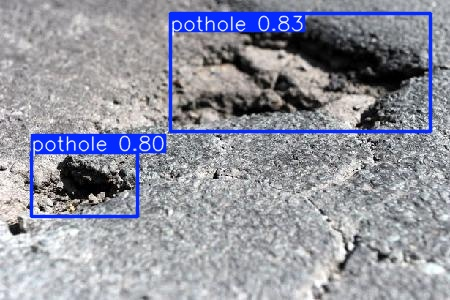

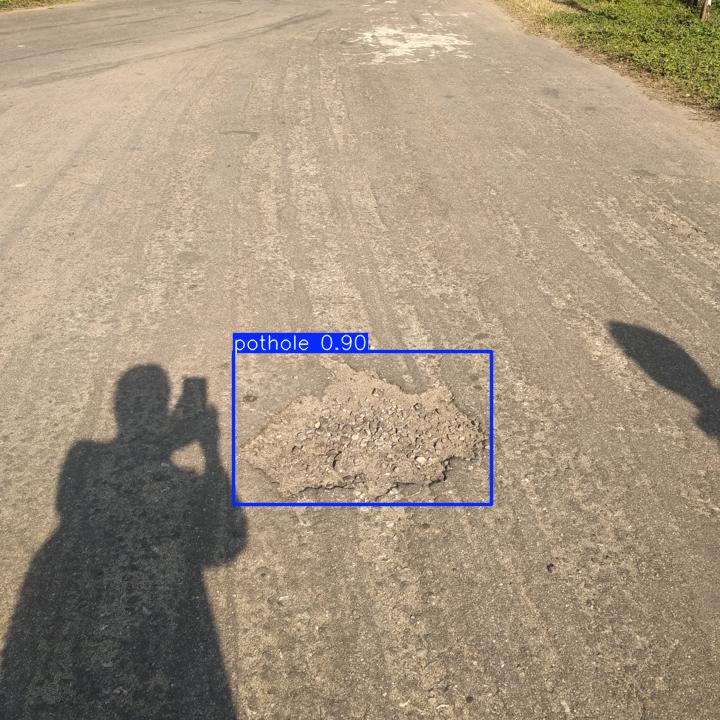

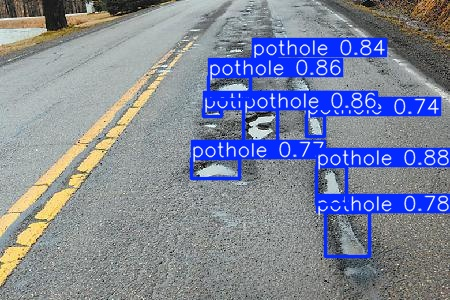

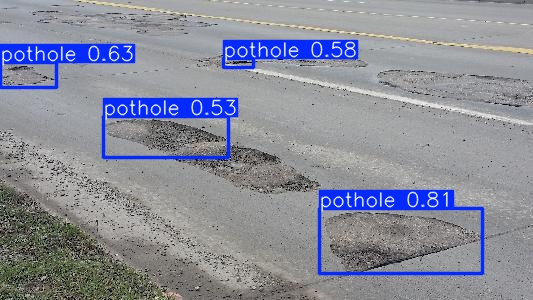

In [ ]:
import glob
from IPython.display import display, Image

prediction_images = glob.glob(
    "/content/pothole_predictions/yolo26s_conf_0499/*.jpg"
)

for img in prediction_images[:5]:
    display(Image(filename=img))

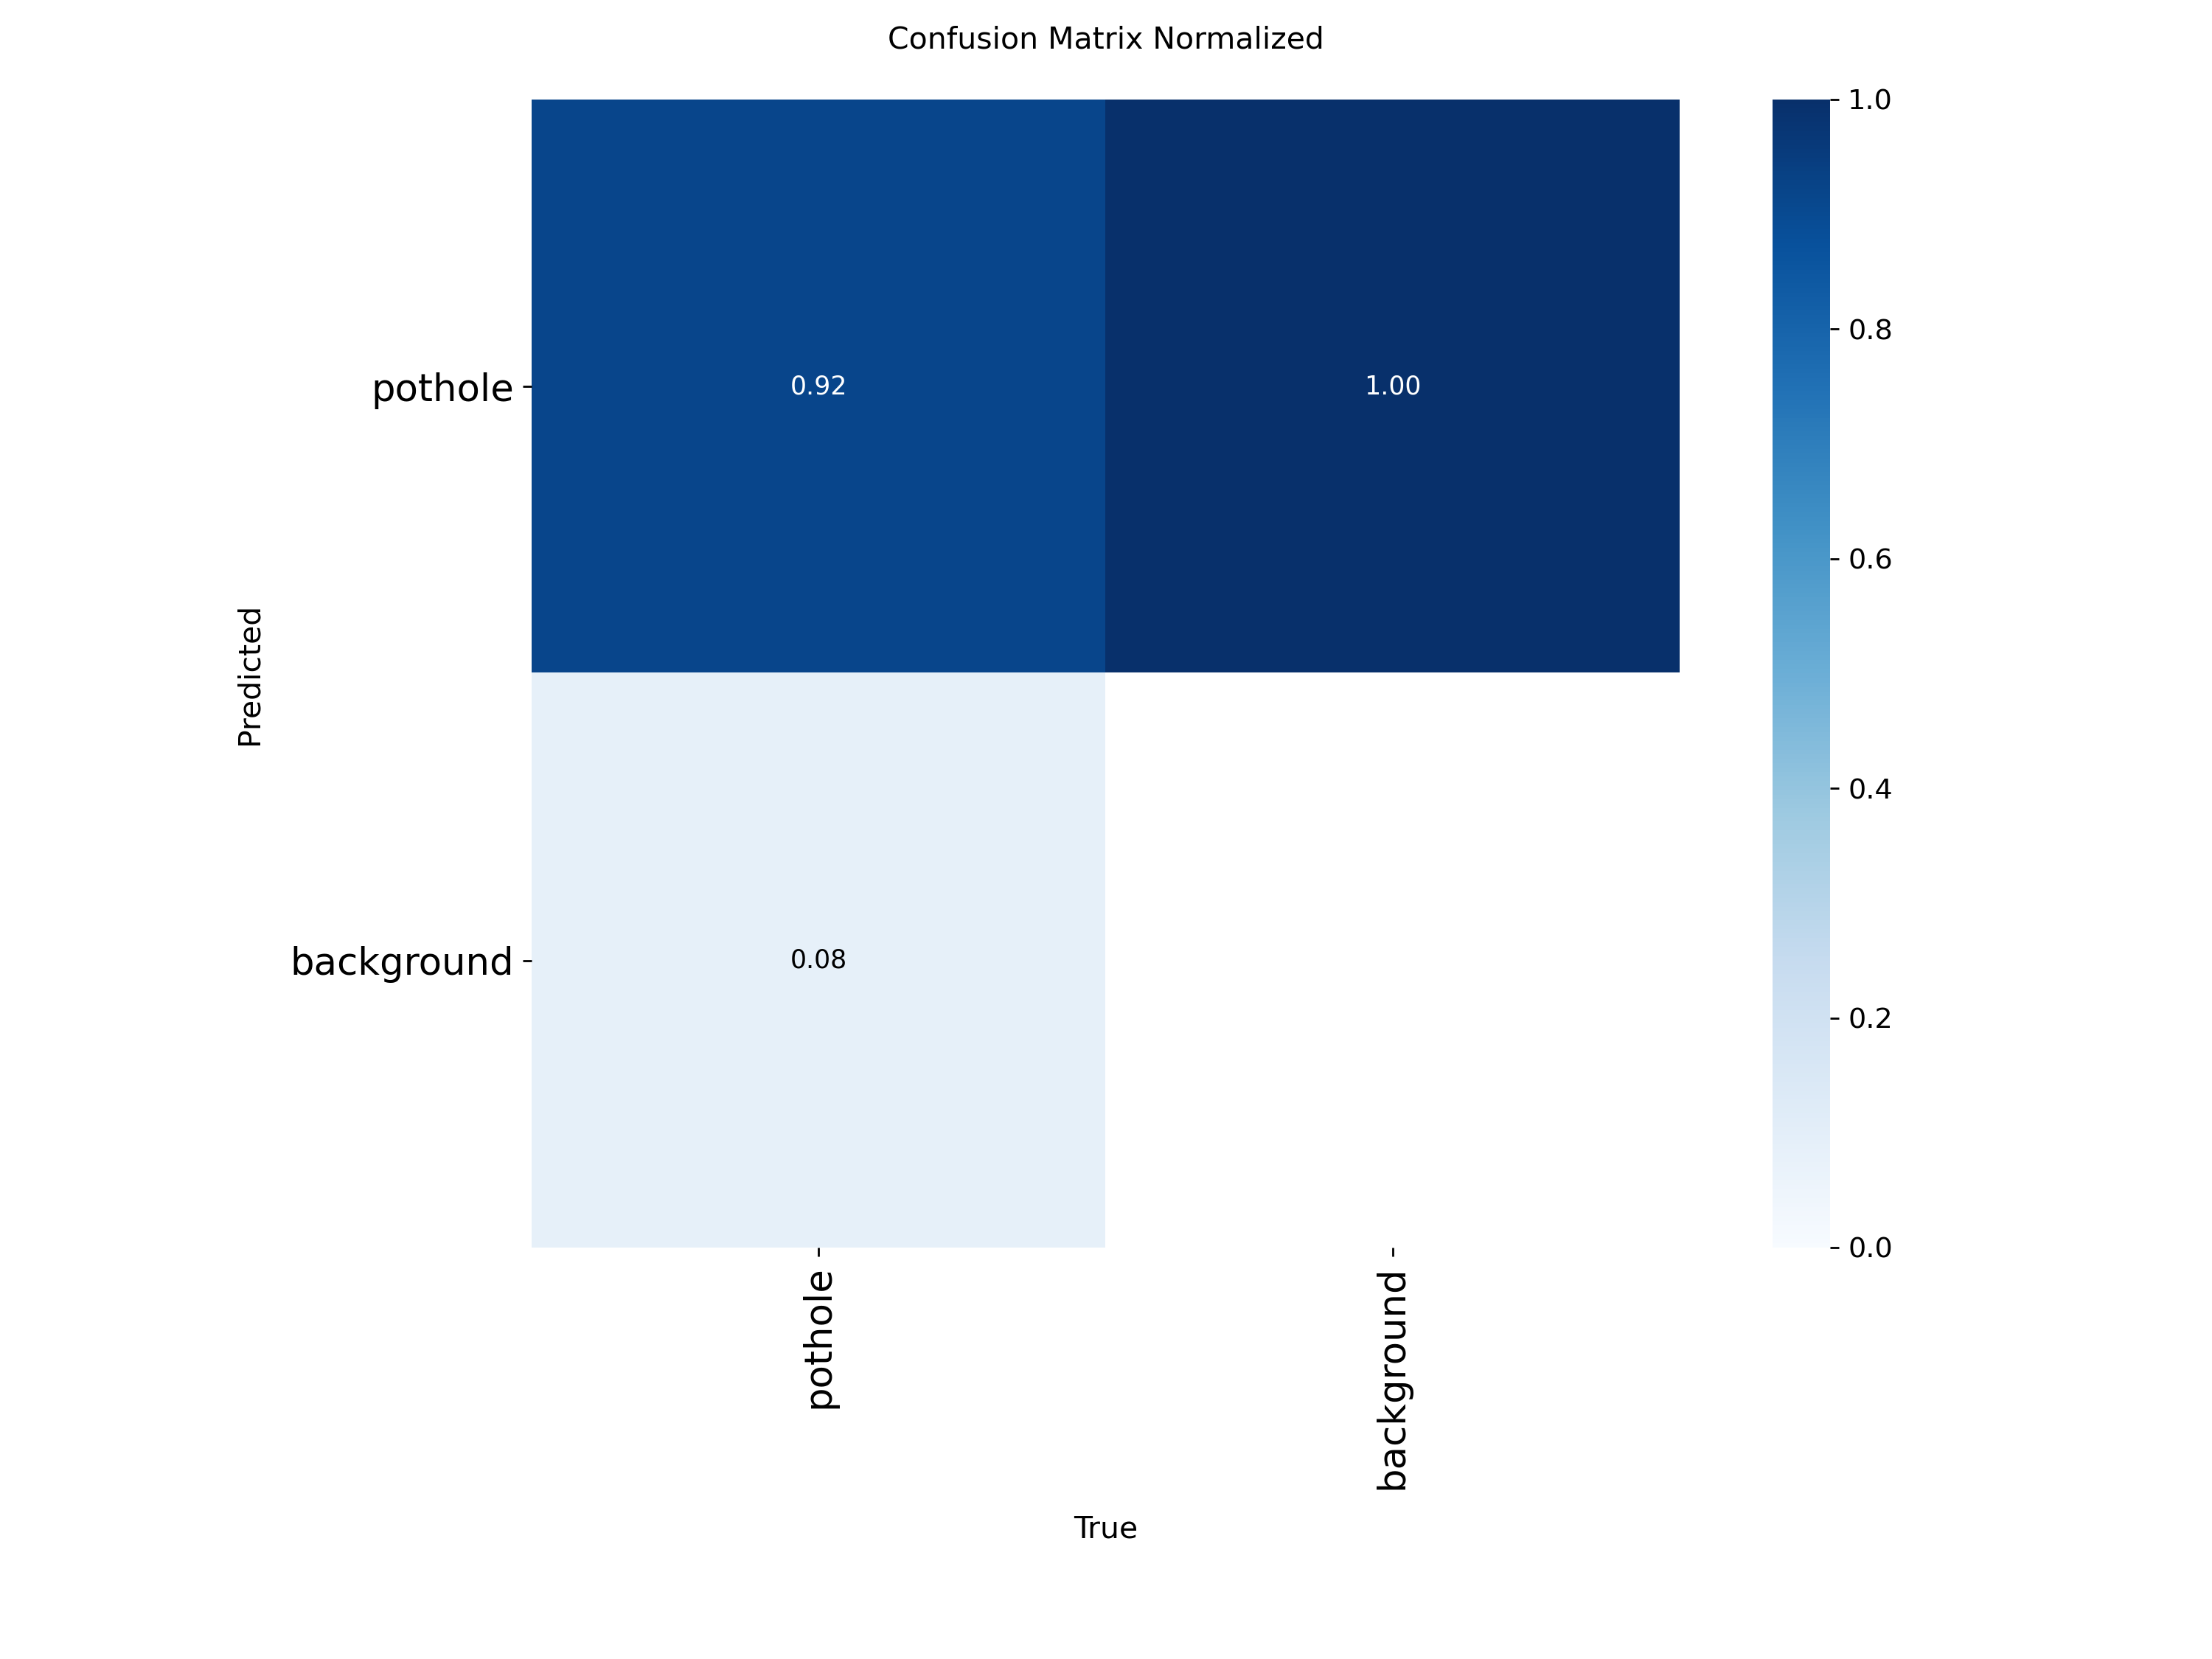

In [ ]:
from IPython.display import display, Image

display(Image(
    filename="/content/runs/detect/val-7/confusion_matrix_normalized.png"
))

In [ ]:
from ultralytics import YOLO

model = YOLO(
    "/content/runs/pothole/yolo26s_baseline/weights/best.pt"
)

results = model.predict(
    source="/content/pothole_dataset/test/images",
    imgsz=640,
    conf=0.25,
    save=True,
    save_txt=True,
    project="/content/pothole_predictions",
    name="false_positive_analysis"
)

print("Analysis predictions generated!")


image 1/67 /content/pothole_dataset/test/images/img-105_jpg.rf.3fe9dff3d1631e79ecb480ff403bcb86.jpg: 640x640 1 pothole, 18.7ms
image 2/67 /content/pothole_dataset/test/images/img-107_jpg.rf.2e40485785f6e5e2efec404301b235c2.jpg: 640x640 2 potholes, 16.2ms
image 3/67 /content/pothole_dataset/test/images/img-146_jpg.rf.61be25b3053a51f622a244980545df2b.jpg: 640x640 1 pothole, 16.1ms
image 4/67 /content/pothole_dataset/test/images/img-161_jpg.rf.211541e7178a4a93ec0680f26b905427.jpg: 640x640 2 potholes, 16.1ms
image 5/67 /content/pothole_dataset/test/images/img-168_jpg.rf.af3590e07b06b43e91fa53990ff94af3.jpg: 640x640 2 potholes, 16.3ms
image 6/67 /content/pothole_dataset/test/images/img-179_jpg.rf.8632eb0d9b75fefe144829e67b75015a.jpg: 640x640 5 potholes, 16.1ms
image 7/67 /content/pothole_dataset/test/images/img-195_jpg.rf.f77a8f4d432a9a89235168ff8e09a650.jpg: 640x640 4 potholes, 16.1ms
image 8/67 /content/pothole_dataset/test/images/img-196_jpg.rf.c1e105382a0bb8d329959cea45173cdf.jpg: 640x

In [ ]:
import os
import glob

image_dir = "/content/pothole_dataset/test/images"
label_dir = "/content/pothole_dataset/test/labels"

prediction_dir = "/content/pothole_predictions/false_positive_analysis/labels"

images = glob.glob(image_dir + "/*")

for img in images:
    filename = os.path.splitext(os.path.basename(img))[0]

    gt_file = os.path.join(label_dir, filename + ".txt")
    pred_file = os.path.join(prediction_dir, filename + ".txt")

    gt_count = 0
    pred_count = 0

    if os.path.exists(gt_file):
        with open(gt_file, "r") as f:
            gt_count = len(f.readlines())

    if os.path.exists(pred_file):
        with open(pred_file, "r") as f:
            pred_count = len(f.readlines())

    if gt_count != pred_count:
        print(
            filename,
            "| Actual:", gt_count,
            "| Predicted:", pred_count
        )

img-634_jpg.rf.42d6e4ebdda859ab935130b75ae5808f | Actual: 13 | Predicted: 8
img-397_jpg.rf.a566bd12530cf6093cd6329a2b4c9e7d | Actual: 3 | Predicted: 7
img-588_jpg.rf.a1673547626abed4ad61089fa41b0365 | Actual: 1 | Predicted: 4
img-44_jpg.rf.c0be863d6030f5d0cb241331c14ee532 | Actual: 2 | Predicted: 3
img-107_jpg.rf.2e40485785f6e5e2efec404301b235c2 | Actual: 1 | Predicted: 2
img-36_jpg.rf.47f0fb502327ec69d5a041581727a149 | Actual: 1 | Predicted: 2
img-336_jpg.rf.eeafb6921ceff278aa8e24afe9f78f8a | Actual: 3 | Predicted: 4
img-264_jpg.rf.a98f3f39b1afdea9ce3155bbe107c6c1 | Actual: 1 | Predicted: 0
img-105_jpg.rf.3fe9dff3d1631e79ecb480ff403bcb86 | Actual: 2 | Predicted: 1
img-350_jpg.rf.643e7315948dd95c0787f6dc5c938ff3 | Actual: 5 | Predicted: 4
img-343_jpg.rf.64b8e5ed7aa9153427c52de5812b3ab2 | Actual: 1 | Predicted: 0
img-415_jpg.rf.2285ec32b9bdc584221e193dc135e3fd | Actual: 3 | Predicted: 2
img-410_jpg.rf.5f10f2bbde7900b5348aeaed6116b901 | Actual: 1 | Predicted: 2
img-47_jpg.rf.53aba5861cc3

In [ ]:
import os
import glob
import numpy as np

GT_DIR = "/content/pothole_dataset/test/labels"

PRED_DIR = "/content/pothole_predictions/false_positive_analysis/labels"

def calculate_iou(box1, box2):

    x1 = box1[0] - box1[2] / 2
    y1 = box1[1] - box1[3] / 2
    x2 = box1[0] + box1[2] / 2
    y2 = box1[1] + box1[3] / 2

    x3 = box2[0] - box2[2] / 2
    y3 = box2[1] - box2[3] / 2
    x4 = box2[0] + box2[2] / 2
    y4 = box2[1] + box2[3] / 2

    xi1 = max(x1, x3)
    yi1 = max(y1, y3)
    xi2 = min(x2, x4)
    yi2 = min(y2, y4)

    intersection = max(0, xi2-xi1) * max(0, yi2-yi1)

    area1 = (x2-x1) * (y2-y1)
    area2 = (x4-x3) * (y4-y3)

    union = area1 + area2 - intersection

    return intersection / union if union > 0 else 0


TP = 0
FP = 0
FN = 0

for gt_file in glob.glob(GT_DIR + "/*.txt"):

    filename = os.path.basename(gt_file)
    pred_file = os.path.join(PRED_DIR, filename)

    with open(gt_file) as f:
        gt = [
            [int(x[0]), *map(float, x[1:5])]
            for line in f if len(x := line.split()) >= 5
        ]

    predictions = []

    if os.path.exists(pred_file):
        with open(pred_file) as f:
            predictions = [
                [int(x[0]), *map(float, x[1:5])]
                for line in f if len(x := line.split()) >= 5
            ]

    matched_gt = set()
    matched_pred = set()

    candidates = []

    for i, g in enumerate(gt):
        for j, p in enumerate(predictions):
            if g[0] == p[0]:
                iou = calculate_iou(g[1:5], p[1:5])
                if iou >= 0.50:
                    candidates.append((iou, i, j))

    for iou, i, j in sorted(candidates, reverse=True):
        if i not in matched_gt and j not in matched_pred:
            matched_gt.add(i)
            matched_pred.add(j)

    TP += len(matched_gt)
    FN += len(gt) - len(matched_gt)
    FP += len(predictions) - len(matched_pred)

print("YOLO26s ERROR ANALYSIS")
print("----------------------")
print("True Positives:", TP)
print("False Positives:", FP)
print("False Negatives:", FN)
print("IoU threshold: 0.50")

YOLO26s ERROR ANALYSIS
----------------------
True Positives: 123
False Positives: 41
False Negatives: 31
IoU threshold: 0.50


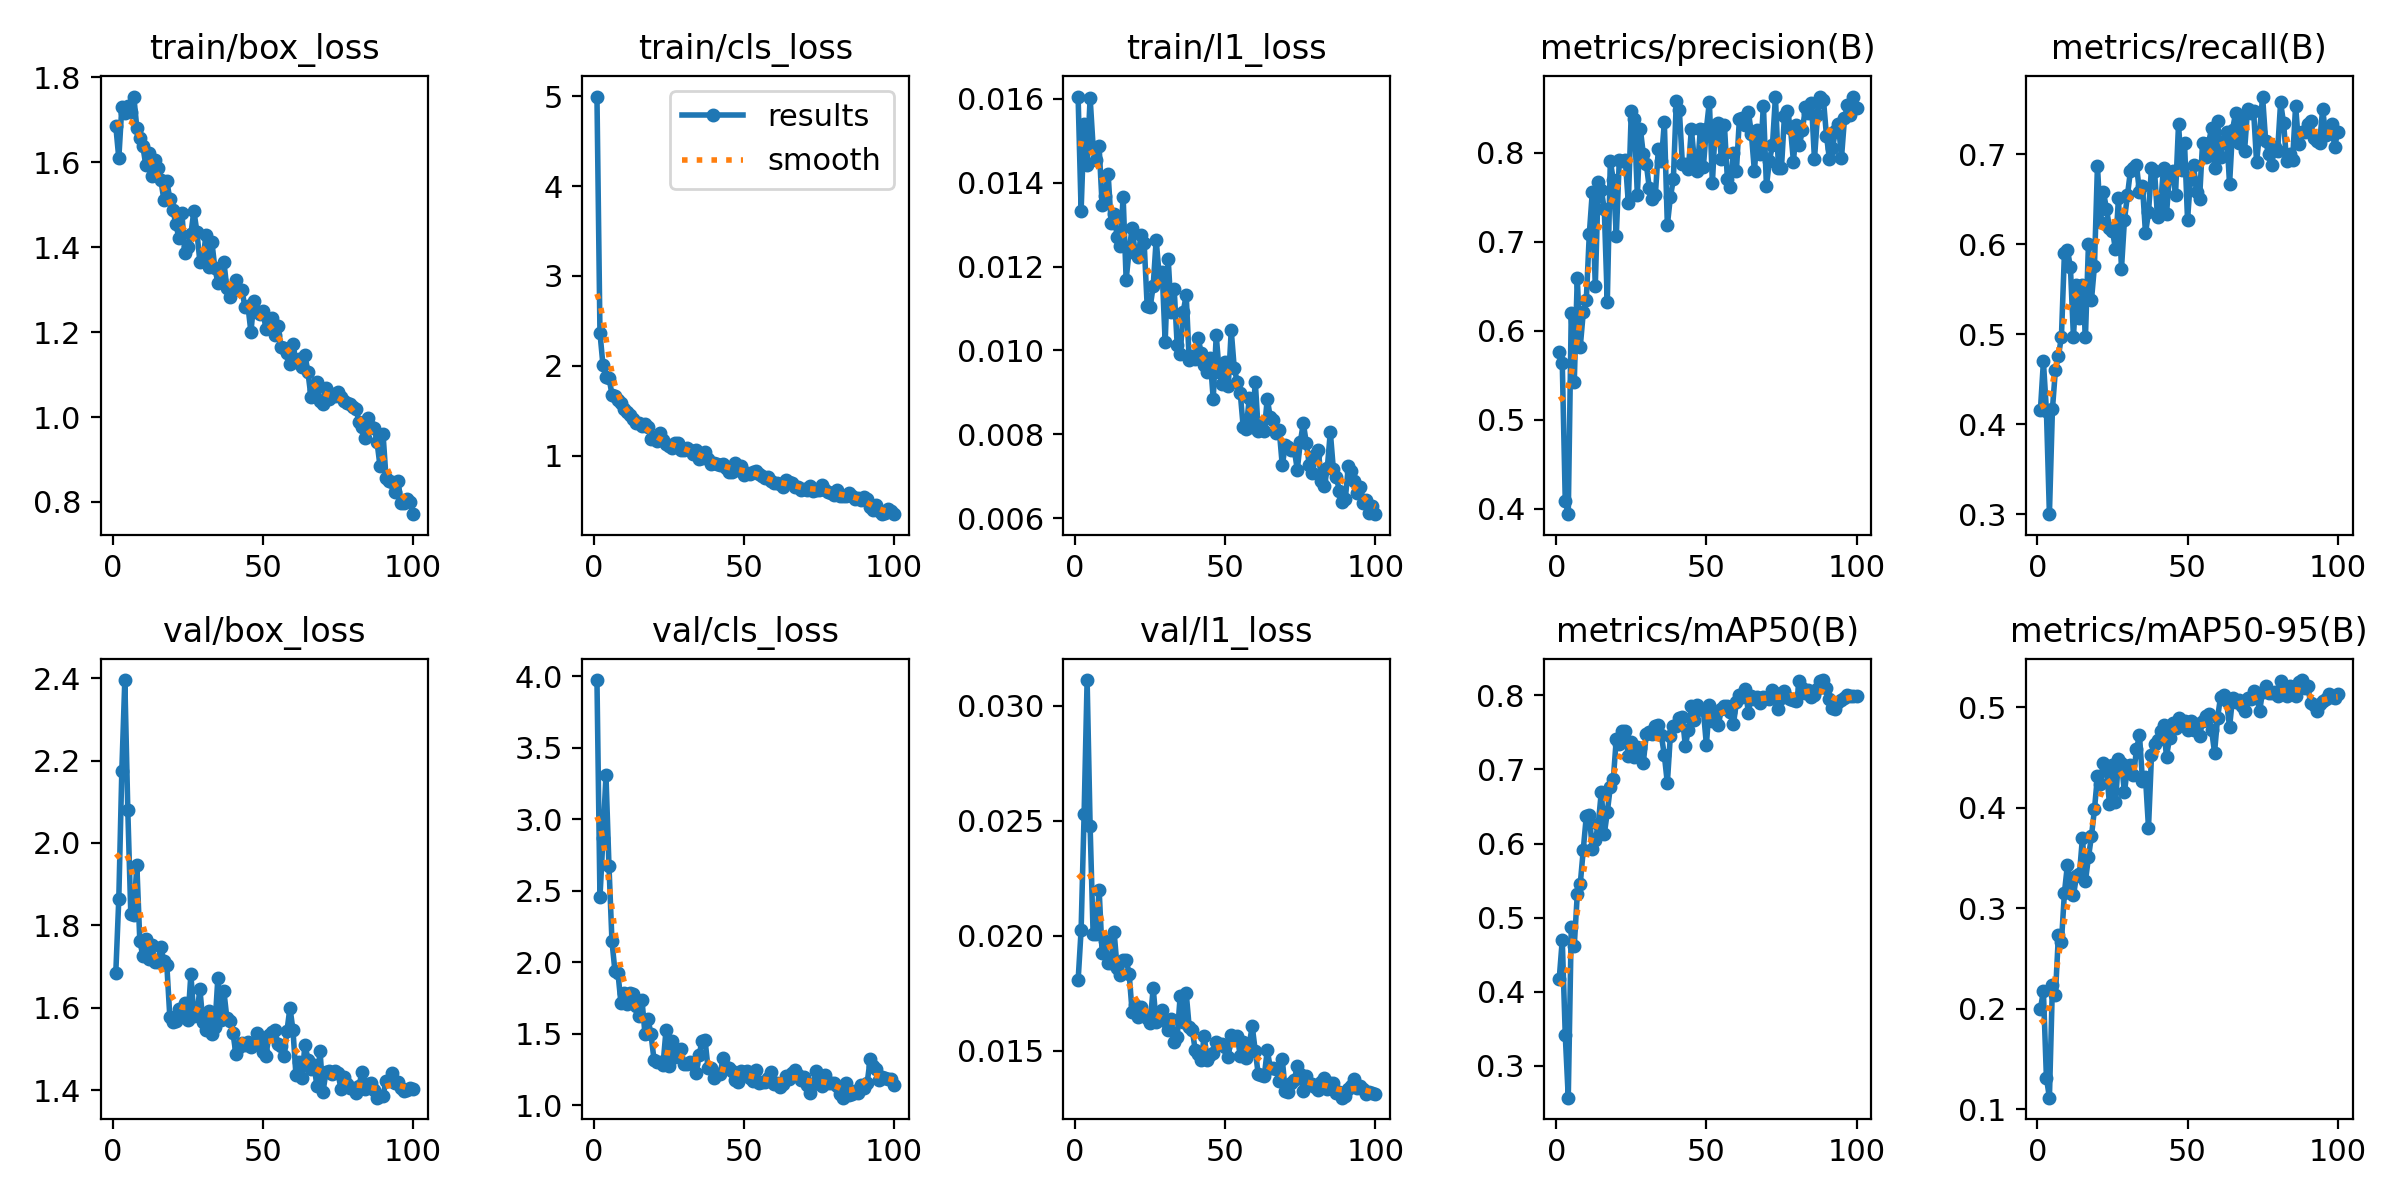

In [ ]:
from IPython.display import display, Image

display(
    Image(filename="/content/runs/pothole/yolo26s_baseline/results.png")
)

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

import os
import shutil

models = {
    "YOLOv8s_640": "/content/runs/pothole/yolov8s_100_epochs/weights/best.pt",
    "YOLOv8s_800": "/content/runs/pothole/yolov8s_improved/weights/best.pt",
    "YOLO11s_640": "/content/runs/pothole/yolo11s_baseline/weights/best.pt",
    "YOLO26s_640": "/content/runs/pothole/yolo26s_baseline/weights/best.pt"
}

save_dir = "/content/drive/MyDrive/Pothole_Research/Models"
os.makedirs(save_dir, exist_ok=True)

for name, path in models.items():
    if os.path.exists(path):
        destination = os.path.join(save_dir, name + ".pt")
        shutil.copy2(path, destination)
        print(f"Saved: {name}")
    else:
        print(f"Checkpoint not found: {name}")

print("Backup process completed!")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Saved: YOLOv8s_640
Saved: YOLOv8s_800
Saved: YOLO11s_640
Saved: YOLO26s_640
Backup process completed!


In [1]:
import os

path = "/content/runs/pothole/yolo26s_baseline/weights/best.pt"

if os.path.exists(path):
    print("SUCCESS! Your trained YOLO26s model is available.")
else:
    print("Model not found in this runtime.")

Model not found in this runtime.


In [2]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [3]:
import os

for root, dirs, files in os.walk('/content/drive/MyDrive'):
    for file in files:
        if file.endswith('.pt'):
            print(os.path.join(root, file))

/content/drive/MyDrive/best.pt
/content/drive/MyDrive/Pothole_YOLOv8/weights/best.pt
/content/drive/MyDrive/Pothole_Research/Models/YOLOv8s_640.pt
/content/drive/MyDrive/Pothole_Research/Models/YOLOv8s_800.pt
/content/drive/MyDrive/Pothole_Research/Models/YOLO11s_640.pt
/content/drive/MyDrive/Pothole_Research/Models/YOLO26s_640.pt


In [4]:
from google.colab import files

model_path = "/content/drive/MyDrive/Pothole_Research/Models/YOLO26s_640.pt"

files.download(model_path)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>